<a href="https://colab.research.google.com/github/bhatprajwal1328-debug/project-6_CNN/blob/main/CNNProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# libraries
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# load
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
print(x_train.shape)
print(y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 214s 1us/step
(50000, 32, 32, 3)
(10000, 1)
(50000, 32, 32, 3)
(10000, 1)


In [ ]:
# normalize the CIFAR-10 dataset (keeping native 32x32x3 shape)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
print(x_train.shape)
print(x_test.shape)

(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [ ]:
# Build  the cnn architecture
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Rebuild model to match CIFAR-10 shape (32, 32, 3)
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(x_train, y_train, epochs=50, validation_data=(x_test, y_test))

Epoch 1/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.4945 - loss: 1.4088 - val_accuracy: 0.6021 - val_loss: 1.1371
Epoch 2/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6243 - loss: 1.0727 - val_accuracy: 0.6502 - val_loss: 1.0073
Epoch 3/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.6723 - loss: 0.9487 - val_accuracy: 0.6635 - val_loss: 0.9710
Epoch 4/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7008 - loss: 0.8628 - val_accuracy: 0.6943 - val_loss: 0.8949
Epoch 5/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7247 - loss: 0.7895 - val_accuracy: 0.6881 - val_loss: 0.9173
Epoch 6/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7436 - loss: 0.7313 - val_accuracy: 0.6948 - val_loss: 0.9016
Epoch 7/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7630 - loss: 0.6796 - val_accuracy: 0.7086 - val_loss: 0.8750
Epoch 8/50
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7807 - loss: 0.6280 -

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Prediction digit: 3
Actual Digit: [3]


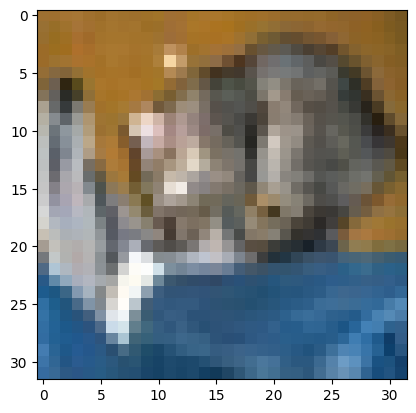

In [ ]:
prediction = model.predict(x_test[:1])
print("Prediction digit:", np.argmax(prediction[0]))
print("Actual Digit:", y_test[0])
# Display the CIFAR-10 color image directly without reshaping
plt.imshow(x_test[0])
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


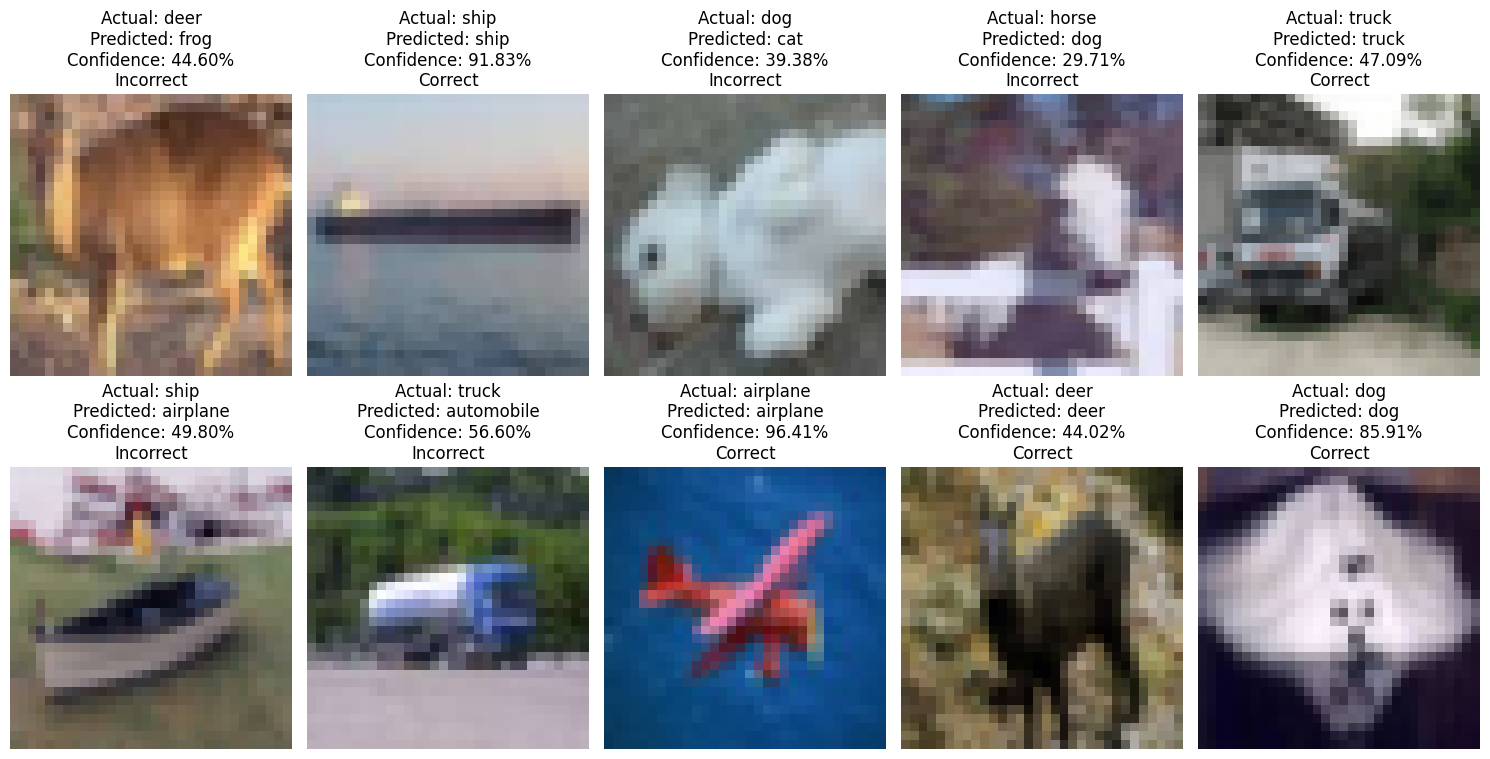

In [ ]:
# Define the CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Select 10 images randomly
indices = np.random.choice(len(x_test), 10, replace=False)

# Get selected images
sample_images = x_test[indices]
actual_labels = y_test[indices].flatten()

# Make predictions
predictions = model.predict(sample_images)

# Get predicted class
predicted_labels = np.argmax(predictions, axis=1)

# Display results
plt.figure(figsize=(15, 8))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(sample_images[i])

    actual = class_names[actual_labels[i]]
    predicted = class_names[predicted_labels[i]]

    confidence = np.max(predictions[i]) * 100

    if actual_labels[i] == predicted_labels[i]:
        result = "Correct"
    else:
        result = "Incorrect"

    plt.title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.2f}%\n"
        f"{result}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [24]:
correct = np.sum(actual_labels == predicted_labels)
total = len(actual_labels)

incorrect = total - correct
accuracy = (correct / total) * 100

print("PREDICTION SUMMARY")
print("-------------------")
print("Total Images:", total)
print("Correct Predictions:", correct)
print("Incorrect Predictions:", incorrect)
print("Accuracy:", round(accuracy, 2), "%")


PREDICTION SUMMARY
-------------------
Total Images: 10
Correct Predictions: 5
Incorrect Predictions: 5
Accuracy: 50.0 %
